IoT Sensor Data Validator Project

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 

warnings.filterwarnings('ignore')

Load Dataset


In [2]:
df = pd.read_csv('Data\iot_telemetry_data.csv')

Data cleaning

In [4]:
df.head()

,ts,device,co,humidity,light,lpg,motion,smoke,temp
0,1.594512e+09,b8:27:eb:bf:9d:51,0.004956,51.000000,False,0.007651,False,0.020411,22.700000
1,1.594512e+09,00:0f:00:70:91:0a,0.002840,76.000000,False,0.005114,False,0.013275,19.700001
2,1.594512e+09,b8:27:eb:bf:9d:51,0.004976,50.900000,False,0.007673,False,0.020475,22.600000
3,1.594512e+09,1c:bf:ce:15:ec:4d,0.004403,76.800003,True,0.007023,False,0.018628,27.000000
4,1.594512e+09,b8:27:eb:bf:9d:51,0.004967,50.900000,False,0.007664,False,0.020448,22.600000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 405184 entries, 0 to 405183
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   ts        405184 non-null  float64
 1   device    405184 non-null  str    
 2   co        405184 non-null  float64
 3   humidity  405184 non-null  float64
 4   light     405184 non-null  bool   
 5   lpg       405184 non-null  float64
 6   motion    405184 non-null  bool   
 7   smoke     405184 non-null  float64
 8   temp      405184 non-null  float64
dtypes: bool(2), float64(6), str(1)
memory usage: 29.0 MB


In [5]:
df.shape

(405184, 9)

In [6]:
df.isnull().sum()

ts          0
device      0
co          0
humidity    0
light       0
lpg         0
motion      0
smoke       0
temp        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(13)

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(405171, 9)

Exploratory Data Analysis

In [10]:
print("Unique Devices:", df["device"].nunique())

print("\nDevice-wise Record Count:")
print(df["device"].value_counts())

Unique Devices: 3

Device-wise Record Count:
device
b8:27:eb:bf:9d:51    187443
00:0f:00:70:91:0a    111815
1c:bf:ce:15:ec:4d    105913
Name: count, dtype: int64


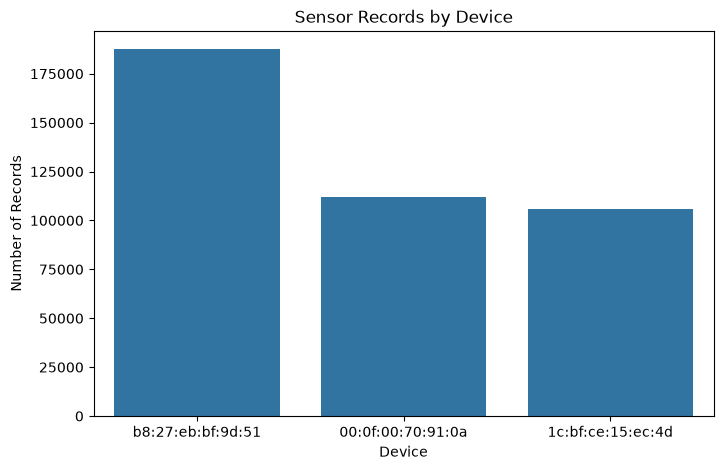

In [11]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="device")

plt.title("Sensor Records by Device")
plt.xlabel("Device")
plt.ylabel("Number of Records")

plt.show()

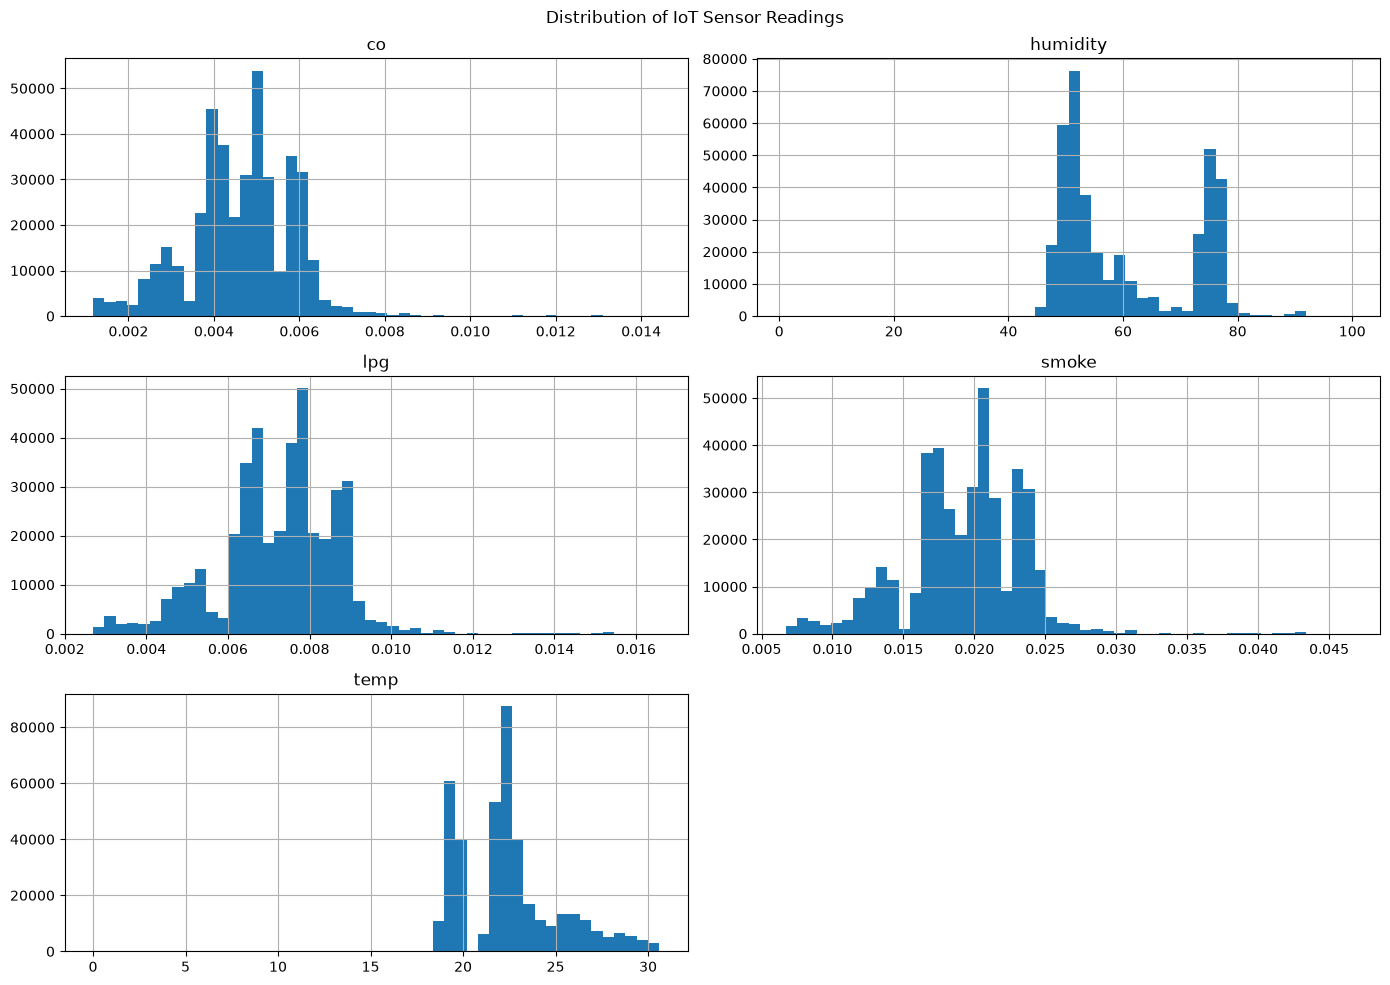

In [12]:
sensor_cols = ["co", "humidity", "lpg", "smoke", "temp"]

df[sensor_cols].hist(
    figsize=(14, 10),
    bins=50
)

plt.suptitle("Distribution of IoT Sensor Readings")
plt.tight_layout()
plt.show()